# DESI DR1 quasar VAC: catalog overview

This notebook reads the DESI DR1 quasar value-added catalog (VAC), lists its columns, and plots the
distributions of a few quasar properties: redshift, bolometric luminosity, black hole mass and Eddington ratio.

Download the catalog from the link in the [README](README.md) and put it in the `download` folder
(or change `vac_file` below).

In [1]:
import numpy as np
from astropy.io import fits
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator
import warnings
warnings.filterwarnings("ignore")

from qsofunc import set_mpl_style, plot_density
set_mpl_style()

## Read the catalog

In [ ]:
vac_file = 'path_to_VAC/desi_dr1_Sep26_z_final.fits'

with fits.open(vac_file) as hdul:
    hdul.info()
vac = fits.getdata(vac_file, 1)
print(f'{len(vac)} spectra of {len(np.unique(vac.TARGETID))} unique quasars (TARGETID)')

Filename: /data3/qiaoya/qsofit/DESI_DR1/compilation/desi_dr1_Sep26_z_final.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU       4   ()      
  1                1 BinTableHDU    332   1774723R x 162C   [8A, 8A, J, K, D, D, 42A, D, D, I, 20A, D, D, D, 8D, 8D, D, D, D, 5D, 5D, 6D, 6D, 2D, 2D, D, D, D, D, D, D, D, D, D, D, D, D, 2D, D, D, D, 5D, 6D, 6D, 6D, 6D, 6D, 6D, 6D, 6D, 6D, 6D, 6D, 6D, 6D, 6D, 6D, 6D, 6D, 6D, 6D, 6D, 6D, 6D, 6D, 6D, 6D, 6D, 6D, 6D, 6D, 6D, 6D, 6D, 6D, 6D, 6D, 6D, 6D, 6D, 6D, 6D, 6D, 6D, 6D, 6D, 6D, 6D, 6D, 6D, 6D, 6D, 6D, 6D, 6D, 6D, 6D, 6D, 6D, 6D, 6D, 6D, 6D, 6D, 6D, 6D, 6D, 6D, 6D, 6D, 6D, 6D, 6D, 6D, 6D, 6D, 6D, 6D, 6D, 6D, 6D, 6D, 6D, 6D, 6D, 6D, 6D, 6D, 2D, 2D, 2D, 2D, 2D, 2D, 2D, 2D, 2D, 2D, 2D, 2D, 2D, 2D, 2D, 2D, 2D, 2D, 2D, 2D, 2D, D, D, D, D, D, D, D, D, D, D, D, D, I]   
1774723 spectra of 1717774 unique quasars (TARGETID)


## List the columns

Each row is one DESI spectrum (`SURVEY`-`PROGRAM`-`HEALPIX`-`TARGETID`, joined in `OBJID`); an object observed in
several survey/program combinations appears more than once. The full description of each column is in the README.

Notes on the format:
- Line columns (e.g. `CIV`, `MGII_BR`, `HBETA_BR`) are 6-element arrays:
  `[peak wavelength (A), flux (1e-17 erg/s/cm2), log L_line (erg/s), FWHM (km/s), rest-frame EW (A), 50% flux centroid wavelength (A)]`;
  the `_ERR` columns hold the matching 1-sigma uncertainties.
- A line that is not covered or not fitted has all properties 0 and errors -1.
- Missing values: continuum luminosities `LOGL*` = -1; `LOGLBOL` and `LOGMBH*` = 0; `LOGLLEDD_RATIO` = -999;
  host-galaxy columns = -1 for objects without a host decomposition ($z>1$).
- `*_STAT` columns are `[number of pixels, reduced chi2]` of each line-complex (or local) fit.

In [3]:
for col in vac.columns:
    print(f'{col.name:22s}{col.format}')

SURVEY                8A
PROGRAM               8A
HEALPIX               J
TARGETID              K
Z_AGNCAT              D
Z_LYA                 D
OBJID                 42A
RA                    D
DEC                   D
IN_SDSS_DR16Q         I
SDSS_DR16Q_OBJID      20A
Z_FIT                 D
Z_SYS                 D
Z_SYS_ERR             D
Z_SYS_LINES           8D
Z_SYS_LINES_ERR       8D
SN_RATIO_CONTI        D
SNR_ALL_MEDIAN        D
EBV                   D
CONTI_PARA            5D
CONTI_PARA_ERR        5D
FE_UV_OPT_PARA        6D
FE_UV_OPT_PARA_ERR    6D
FE_UV_EW              2D
FE_OPT_EW             2D
LOGL1350              D
LOGL1350_ERR          D
LOGL1700              D
LOGL1700_ERR          D
LOGL2500              D
LOGL2500_ERR          D
LOGL3000              D
LOGL3000_ERR          D
LOGL4200              D
LOGL4200_ERR          D
LOGL5100              D
LOGL5100_ERR          D
CONTI_FIT_STAT        2D
FRAC_HOST_4200        D
FRAC_HOST_5100        D
DN4000                D
H

### Look at one object

In [4]:
row = vac[vac.OBJID == 'main-dark-36522-39627334138987461'][0]
for name in ['OBJID', 'TARGETID', 'RA', 'DEC', 'Z_FIT', 'Z_SYS', 'Z_SYS_ERR', 'SNR_ALL_MEDIAN',
             'LOGL1350', 'LOGL3000', 'LOGLBOL', 'LOGMBH_MGII', 'LOGMBH_CIV', 'LOGMBH', 'LOGLLEDD_RATIO']:
    print(f'{name:16s}', row[name])

prop_names = ['peak', 'flux', 'logL', 'FWHM', 'EW', 'centroid']
for line in ['CIV', 'MGII_BR']:
    print(line)
    for p, v, e in zip(prop_names, row[line], row[line+'_ERR']):
        print(f'   {p:9s} {v:10.2f} +- {e:.2f}')

OBJID            main-dark-36522-39627334138987461
TARGETID         39627334138987461
RA               22.989345331428684
DEC              -19.06538134636261
Z_FIT            2.3541899553657344
Z_SYS            2.3582071766912076
Z_SYS_ERR        0.0033133559591766023
SNR_ALL_MEDIAN   8.111598013169814
LOGL1350         45.975569864281596
LOGL3000         -1.0
LOGLBOL          46.55649483995722
LOGMBH_MGII      0.0
LOGMBH_CIV       8.968398019327456
LOGMBH           8.968398019327456
LOGLLEDD_RATIO   -0.5122737244878053
CIV
   peak         1546.92 +- 0.23
   flux          790.85 +- 17.82
   logL           44.53 +- 0.01
   FWHM         4272.41 +- 252.34
   EW             55.76 +- 1.27
   centroid     1552.12 +- 0.84
MGII_BR
   peak         2801.46 +- 0.77
   flux          389.17 +- 21.57
   logL           44.22 +- 0.02
   FWHM         4741.35 +- 154.22
   EW             50.58 +- 2.84
   centroid     2805.84 +- 1.19


## Select a sample

Here we keep spectra with a valid systemic redshift, bolometric luminosity and BH mass, and a median S/N per pixel
above 1 (as in the paper figure). Use `Z_SYS` as the redshift: it is the systemic redshift from the line fits where
it is reliable and the DESI pipeline redshift (`Z_FIT`) otherwise (`Z_SYS_ERR = -1` in that case).

In [5]:
z = vac.Z_SYS
lbol = vac.LOGLBOL
mbh = vac.LOGMBH
ledd = vac.LOGLLEDD_RATIO

good = (z > 0) & (lbol > 30) & (mbh > 0) & (vac.SNR_ALL_MEDIAN > 1)
print(f'{good.sum()} of {len(vac)} spectra selected')

1438522 of 1774723 spectra selected


## Redshift distribution

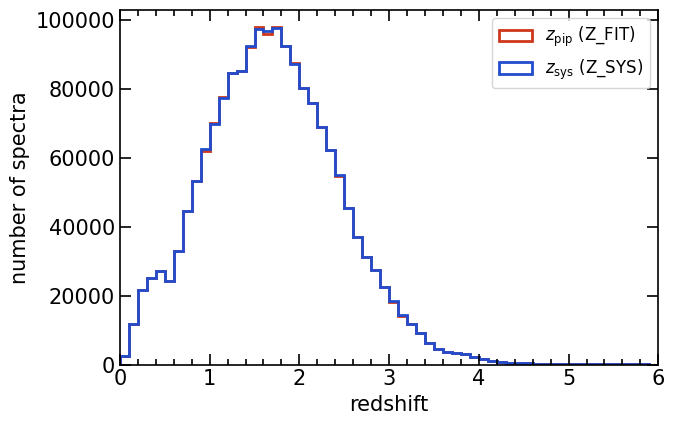

In [6]:
fig, ax = plt.subplots(1, 1, figsize=(7, 4.5))
bins = np.arange(0, 6.01, 0.1)
ax.hist(vac.Z_FIT, bins=bins, histtype='step', lw=2, color='#cd371c', label=r'$z_{\rm pip}$ (Z_FIT)')
ax.hist(vac.Z_SYS, bins=bins, histtype='step', lw=2, color='#214cce', label=r'$z_{\rm sys}$ (Z_SYS)')
ax.set_xlabel('redshift')
ax.set_ylabel('number of spectra')
ax.set_xlim(0, 6)
ax.xaxis.set_major_locator(MultipleLocator(1.)); ax.xaxis.set_minor_locator(MultipleLocator(.2))
ax.legend(fontsize=12)
plt.tight_layout()
plt.show()

## Bolometric luminosity and BH mass vs. redshift

`LOGLBOL` and `LOGMBH` are the fiducial values. The BH mass comes from MgII at $0.6\le z\le2.2$ when available,
otherwise from H$\beta$ at $z<0.8$ or from CIV at $z>1.8$; $L_{\rm bol}$ follows the same rule with
$L_{5100}$, $L_{3000}$ and $L_{1350}$. Host-galaxy decomposition is applied at $z<1$.

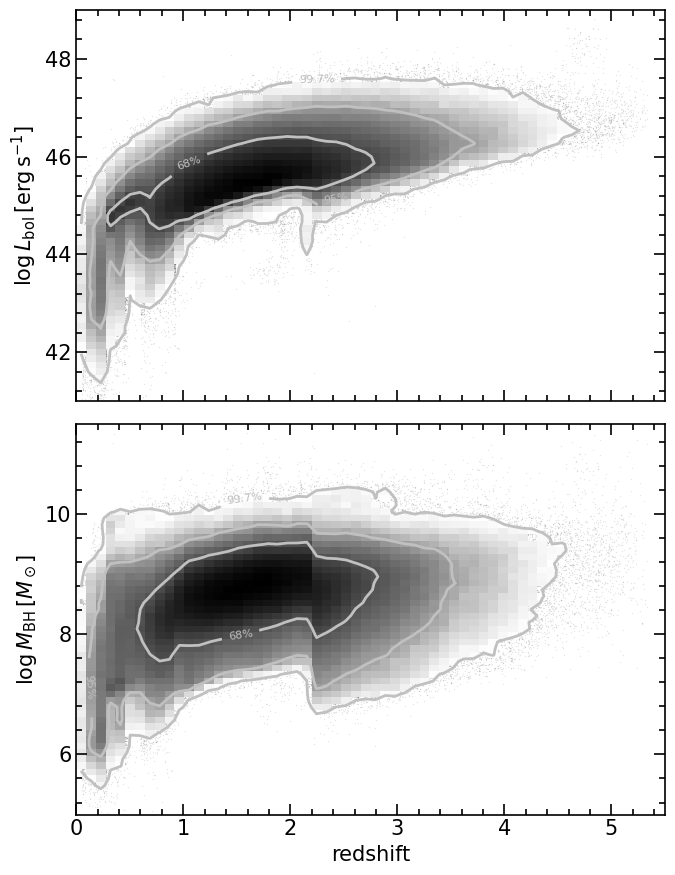

In [7]:
fig, ax = plt.subplots(2, 1, figsize=(7, 9), sharex=True)

plot_density(ax[0], z[good], lbol[good], bins=60, range=[[0, 5.5], [41, 49]])
ax[0].set_ylabel(r'$\log L_{\rm bol}\,[{\rm erg\,s^{-1}}]$')
ax[0].set_ylim(41, 49)
ax[0].yaxis.set_major_locator(MultipleLocator(2.)); ax[0].yaxis.set_minor_locator(MultipleLocator(.4))

plot_density(ax[1], z[good], mbh[good], bins=60, range=[[0, 5.5], [5, 11.5]])
ax[1].set_ylabel(r'$\log M_{\rm BH}\,[M_\odot]$')
ax[1].set_ylim(5, 11.5)
ax[1].yaxis.set_major_locator(MultipleLocator(2.)); ax[1].yaxis.set_minor_locator(MultipleLocator(.4))

ax[1].set_xlim(0, 5.5)
ax[1].set_xlabel('redshift')
ax[1].xaxis.set_major_locator(MultipleLocator(1.)); ax[1].xaxis.set_minor_locator(MultipleLocator(.2))
plt.tight_layout()
plt.show()